# First Assignment - Business Process Prediction Simulation, and Optimization - Winter Semester 2026/2027

### Milena Fernanda Rivera Hernández

### **3.1 Technical Setup and Preliminaries**

In [38]:
# First we will list all the libraries that we will use and for what purpose

# Process mining
import pm4py

# Data frames handling
import pandas as pd

# For defining graph axes
import numpy as np

# Visualizations for additional stats
import matplotlib.pyplot as plt

# Heatmap 
import seaborn as sns

### **3.2 Simple Event Log Analysis**

In [3]:
log = pm4py.read_xes("data_BPIChallenge2017_1_all/BPI Challenge 2017.xes.gz") 
df = pm4py.convert_to_dataframe(log)



/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(
/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 31509/31509 [01:07<00:00, 469.47it/s]


In [4]:
print(df.shape)
df.head(5)

(1202267, 19)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1673366067,withdraw,2016-01-01 09:52:36.392000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1493664571,schedule,2016-01-01 09:52:36.403000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(df["time:timestamp"].dtype)

datetime64[us, UTC]


In [6]:
# To report simple statistics about the data log we must map each 'column/attribute'
case = "case:concept:name"
act = "concept:name"
timestamp = "time:timestamp"
resource = "org:resource"
lifec = "lifecycle:transition"

In [7]:
# Number of cases 
num_cases = df[case].nunique()
print(num_cases) # 31509

31509


In [8]:
# Number of events
num_events = len(df)
print(num_events) # 1202267

1202267


In [9]:
# Number of process variants
num_proc_var = len(pm4py.get_variants(df))
print(num_proc_var)

15930


In [10]:
# Number of distinct case and event attribute labels

# For case
# First we must figure out the attribute labels
case_attributes = [col for col in df.columns if col.startswith("case:")]
# Check line
print(case_attributes)

num_dist_case_labels = len(case_attributes)
print(num_dist_case_labels)

# For event

# NOTE: Metadata lists only the global attributes that every event has. So if we add offer-related ones we have more.
# We should define in which ones we are interested in (global only for example). 
global_categorical_events = ["Action", "EventID", "EventOrigin","concept:name", "lifecycle:transition", "org:resource", "time:timestamp"] # EventID
#event_attributes = [c for c in global_categorical_events if c in df.columns] # 7 attributes

# Real attributes
event_attributes = [c for c in df.columns if not c.startswith("case:") and not c.startswith("@@")] # 15 attributes

# categorical event attributes = non-numeric, non-datetime event-level columns
categorical_event_attributes = df[event_attributes].select_dtypes(include=['object', 'str', 'category']).columns 

# Check line
print(event_attributes)

num_dist_event_labels = len(event_attributes)
print(num_dist_event_labels)

print(categorical_event_attributes)
print(len(categorical_event_attributes))

['case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount']
4
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']
15
Index(['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID',
       'lifecycle:transition', 'Accepted', 'Selected', 'OfferID'],
      dtype='str')
9


In [11]:
# Mean and standard deviation of case length

# First we must figure out events per case
case_len = df.groupby(case).size()

# Mean
cl_mean = case_len.mean()
# Check line
print(cl_mean) # 38.15

# STD
cl_std = case_len.std()
# Check line
print(cl_std) # 16.715

38.15630454790695
16.71530805656438


In [12]:
# Mean and standard deviation of case duration 

# First we must calculate the case duration
# We extract the corresponding timestamps
case_timestamp = df.groupby(case)[timestamp]
durationn = (case_timestamp.max() - case_timestamp.min()).dt.total_seconds() # we should keep it in our finnest granularity which are seconds for further calculations

# days ******

# Mean
mean_days = durationn.mean() / 86400
# Check line
print(mean_days)

# STD
std_days = durationn.std() / 86400
# Check line
print(std_days)

# minutes ****

# Mean
mean_minutes = durationn.mean() / 60
# Check line
print(mean_minutes)

# STD
std_minutes = durationn.std() / 60
# Check line
print(std_minutes)

# seconds *****

# Mean
mean_secs = durationn.mean()
# Check line
print(mean_secs)

# STD
std_secs = durationn.std()
# Check line
print(std_secs)


21.899605591087365
13.1692325332843
31535.432051165804
18963.694847929393
1892125.9230699483
1137821.6908757635


In [13]:
# Number of categorical event attributes
num_cat_events_att = len(categorical_event_attributes)
# Check line
print(num_cat_events_att)

9


In [14]:
# Table with the required statistics

table_4_stats = pd.DataFrame({
    "Statistic": ["Number of cases",
                  "Number of events",
                  "Number of process variants",
                  "Number of distinct case attribute labels",
                  "Number of distinct event attribute labels",
                  "Case length mean", 
                  "Case length std", 
                  "Case duration mean (days)",
                  "Case duration std (days)",
                  "Case duration mean (minutes)",
                  "Case duration std (minutes)",
                  "Case duration mean (seconds)",
                  "Case duration std (seconds)",
                  "Number of categorical event attributes"],
    "Value" :[f"{num_cases:,}",
              f"{num_events:,}",
              f"{num_proc_var:,}",
              num_dist_case_labels,
              num_dist_event_labels,
              f"{cl_mean:.3f}",
              f"{cl_std:.3f}",
              f"{mean_days:.3f}",
              f"{std_days:.3f}",
              f"{mean_minutes:,.3f}",
              f"{std_minutes:,.3f}",
              f"{mean_secs:,.3f}",
              f"{std_secs:,.3f}",
              num_cat_events_att]})

display(table_4_stats)


,Statistic,Value
0,Number of cases,"31,509"
1,Number of events,"1,202,267"
2,Number of process variants,"15,930"
3,Number of distinct case attribute labels,4
4,Number of distinct event attribute labels,15
5,Case length mean,38.156
6,Case length std,16.715
7,Case duration mean (days),21.900
8,Case duration std (days),13.169
9,Case duration mean (minutes),"31,535.432"


#### Additional Statistics

In [15]:
# For what I intent to add as additional statistics it is required a one case-level table so we must build it first

# Access possible actions
print(df[act].unique())


# NOTE: df is sorted by case and timestamp

# duration in days must be calculated using the previous durationn variable
dur_days = durationn / 86400 

# distinct cases can be obtain grouping by the case columns
cases = df.groupby(case).agg(loan_goal=("case:LoanGoal", "first"),
                             app_type=("case:ApplicationType", "first"),
                             amount=("case:RequestedAmount", "first"),
                             n_events=(act, "size"))

cases["duration_days"] = dur_days # NOTE: it is aligned by case ID

# NOTE: The outcome is the last of these activities in each case
outcome_acts = ["A_Pending", "A_Denied", "A_Cancelled"]
last_outcome = (df[df[act].isin(outcome_acts)].groupby(case)[act].last())

# NOTE: 98 cases are applications still open when the log ends, so “No decision yet” says what they are.
cases["outcome"] = last_outcome.reindex(cases.index).fillna("No decision yet")

print(cases["outcome"].value_counts())  

<StringArray>
[      'A_Create Application',                'A_Submitted',
             'W_Handle leads',     'W_Complete application',
                  'A_Concept',                 'A_Accepted',
             'O_Create Offer',                  'O_Created',
   'O_Sent (mail and online)',        'W_Call after offers',
                 'A_Complete',     'W_Validate application',
               'A_Validating',                 'O_Returned',
    'W_Call incomplete files',               'A_Incomplete',
                 'O_Accepted',                  'A_Pending',
                   'A_Denied',                  'O_Refused',
                'O_Cancelled',                'A_Cancelled',
       'O_Sent (online only)',   'W_Assess potential fraud',
 'W_Personal Loan collection',    'W_Shortened completion ']
Length: 26, dtype: str
outcome
A_Pending          17228
A_Cancelled        10431
A_Denied            3752
No decision yet       98
Name: count, dtype: int64


In [16]:
display(cases[:5]) # Line just to visualise the final table

,loan_goal,app_type,amount,n_events,duration_days,outcome
case:concept:name,,,,,,
Application_1000086665,"Other, see explanation",New credit,5000.0,22,32.585593,A_Cancelled
Application_1000158214,Home improvement,New credit,12500.0,25,8.033037,A_Pending
Application_1000311556,Car,New credit,45000.0,18,30.586242,A_Cancelled
Application_1000334415,"Other, see explanation",New credit,5000.0,40,13.629359,A_Denied
Application_1000339879,Existing loan takeover,New credit,37500.0,51,12.843500,A_Pending


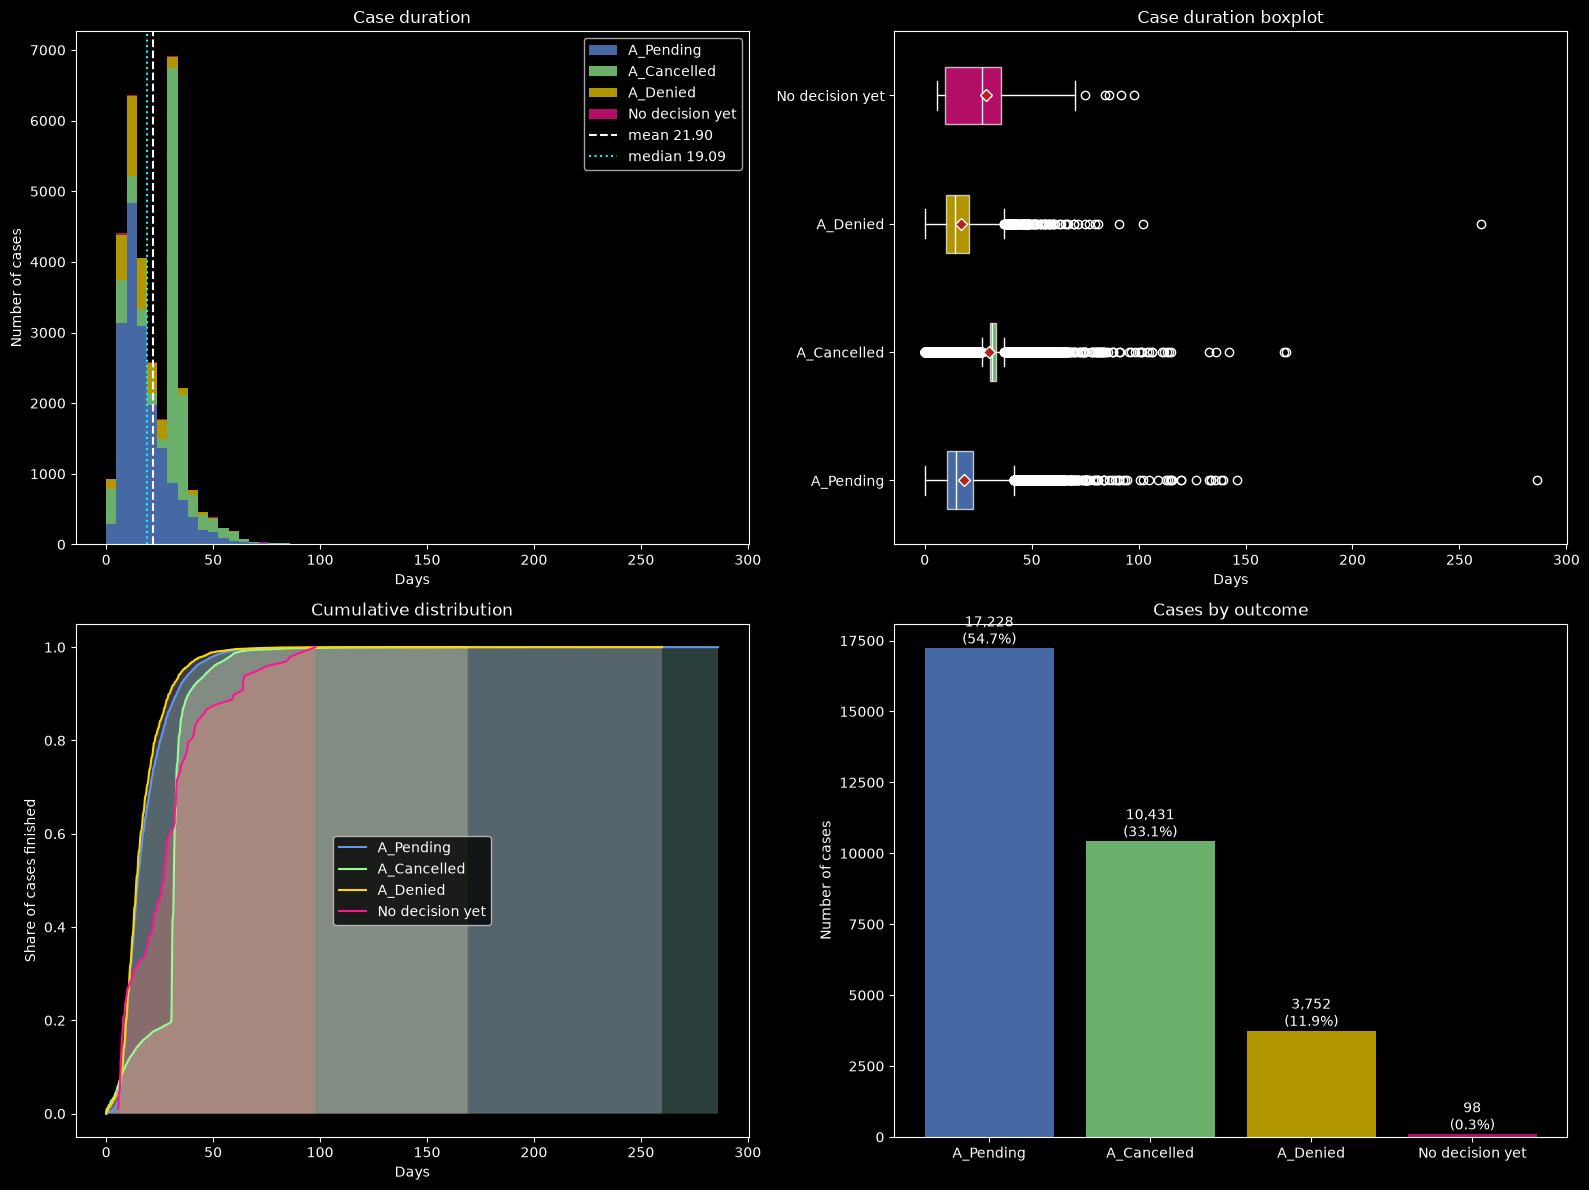

In [33]:
# Case duration & outcome distribution 

duration_in_days = cases["duration_days"]

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# For the outcome
order = ["A_Pending",
         "A_Cancelled",
         "A_Denied",
         "No decision yet"]
colors = {"A_Pending": "cornflowerblue", 
          "A_Cancelled": "palegreen",
          "A_Denied": "gold", 
          "No decision yet": "deeppink"}

# It is required one duration series per outcome, in a fixed order!
groups = {o: cases.loc[cases["outcome"] == o, "duration_days"] for o in order}

# Histogram 

# To have same bin edges for every group
bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()), # a list of series, one per outcome                   
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title="Case duration",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot (one box per outcome)
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): # To pair each box with an order
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") # In order for medians to stay visible
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF - Empirical Cumulative Distribution Function (one curve per outcome)
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome

# First, we calculate the frequencies of each category
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.show()

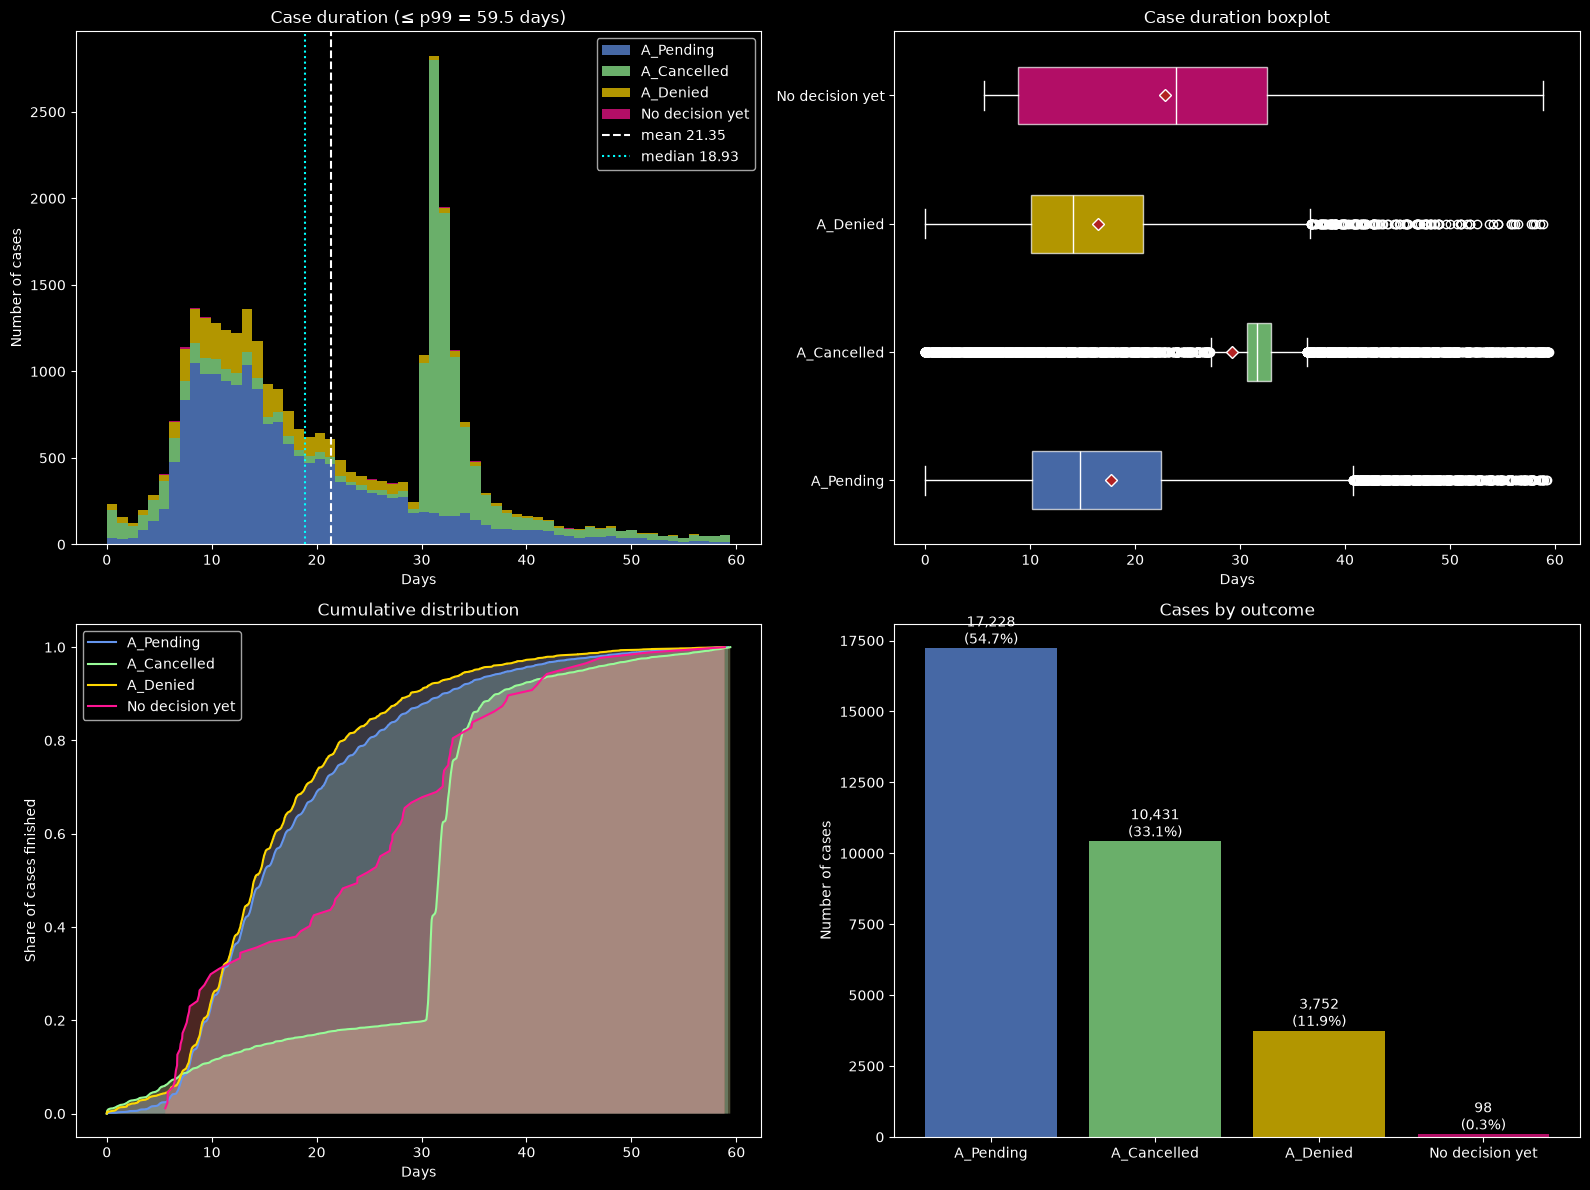

In [32]:
# Changes in graphs with percentil 99
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
p99 = cases["duration_days"].quantile(0.99)
shown = cases[cases["duration_days"] <= p99]
duration_in_days = shown["duration_days"]
groups = {o: shown.loc[shown["outcome"] == o, "duration_days"] for o in order}

# Histogram 

# To have same bin edges for every group
bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()), # a list of series, one per outcome                   
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title=f"Case duration (≤ p99 = {p99:.1f} days)",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot (one box per outcome)
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): # To pair each box with an order
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") # In order for medians to stay visible
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF - Empirical Cumulative Distribution Function (one curve per outcome)
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome

# First, we calculate the frequencies of each category
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.show()

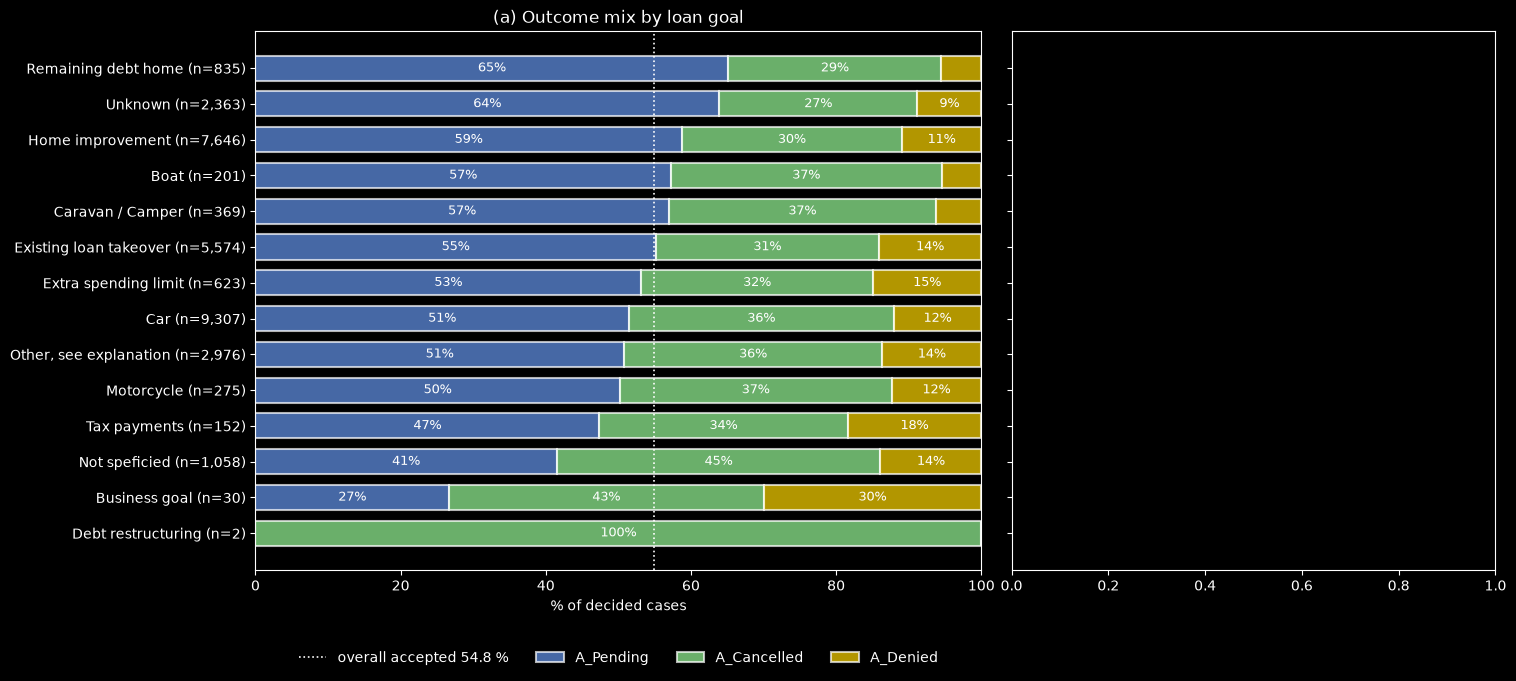

In [ ]:
# Outcome by loan attributes & by application type
outcome = ["A_Pending", 
          "A_Cancelled", 
          "A_Denied"]
# Same colors to keep coherence :)
colors = {"A_Pending": "cornflowerblue", 
          "A_Cancelled": "palegreen",
          "A_Denied": "gold"}

# For this we must only focus on decided cases
decided_cases = cases[cases["outcome"].isin(outcome)].copy() 
decided_cases["accepted"] = decided_cases["outcome"].eq("A_Pending") # Considering cases accepted this way
decided_cases["goal"] = decided_cases["loan_goal"]  

# Resume table (cross-tabulation): otcome mix + acceptance rate per application type
mix = pd.crosstab(decided_cases["goal"], 
                  decided_cases["outcome"], 
                  normalize="index")[outcome] * 100
by_app = decided_cases.groupby(["goal", "app_type"])["accepted"].agg(["mean", "size"]).unstack("app_type")
tab = mix.assign(n=decided_cases["goal"].value_counts())
tab["accepted_new_credit"] = by_app[("mean", "New credit")] * 100
tab["accepted_limit_raise"] = by_app[("mean", "Limit raise")] * 100
tab["share_limit_raise"] = by_app[("size", "Limit raise")] / tab["n"] * 100
tab = tab.sort_values("A_Pending")    

# Figure configuration
plt.style.use("dark_background")
fig, (ax1, ax2) = plt.subplots(1, 2, 
                               figsize=(16, 7), 
                               sharey=True,
                               gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.05})
y = np.arange(len(tab))
labels = [f"{g} (n={int(n):,})" for g, n in zip(tab.index, tab["n"])]

# Stacked bars
left = np.zeros(len(tab))
for o in outcome:
    ax1.barh(y, 
             tab[o], 
             left=left, 
             color=colors[o], 
             height=0.7, 
             label=o, 
             edgecolor="white", 
             linewidth=1.5,
             alpha=0.7)
    for yi, (l, w) in enumerate(zip(left, tab[o])):
        if w >= 8:
            ax1.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += tab[o].values

# Overall calculation
overall = decided_cases["accepted"].mean() * 100
ax1.axvline(overall, 
            color="white", 
            linestyle=":", 
            linewidth=1.2, 
            label=f"overall accepted {overall:.1f} %")
ax1.set(xlim=(0, 100),
        xlabel="% of decided cases", 
        title="(a) Outcome mix by loan goal")
ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.legend(loc="lower center", 
           bbox_to_anchor=(0.5, -0.2), 
           ncol=4, 
           frameon=False)

# Dumbbel "by application type"
for yi, g in enumerate(tab.index):
    nc, lr = tab.loc[g, "accepted_new_credit"], tab.loc[g, "accepted_limit_raise"]
    n_lr = by_app.loc[g, ("size", "Limit raise")]
    n_nc = by_app.loc[g, ("size", "New credit")]
    show_lr = pd.notna(lr)                            # no Limit raise cases for a goal -> no diamond
    show_nc = pd.notna(nc)
    a_lr = 1.0 if show_lr and n_lr >= FADE_BELOW else 0.35
    a_nc = 1.0 if show_nc and n_nc >= FADE_BELOW else 0.35
    if show_lr and show_nc:
        ax2.plot([nc, lr], [yi, yi], color="#8a8a85", linewidth=1.5, alpha=min(a_lr, a_nc), zorder=1)
    if show_lr:
        ax2.scatter(lr, yi, marker="D", s=70, facecolors="none", edgecolors=COL["A_Pending"],
                    linewidths=2, alpha=a_lr, zorder=3)
    if show_nc:
        ax2.scatter(nc, yi, marker="o", s=70, color=COL["A_Pending"], alpha=a_nc, zorder=3)
ax2.axvline(overall, color="white", linestyle=":", linewidth=1.2)
ax2.set(xlim=(-3, 103), xlabel="% accepted (A_Pending)", title="(b) Share accepted by application type")
ax2.tick_params(axis="y", left=False)

plt.show()



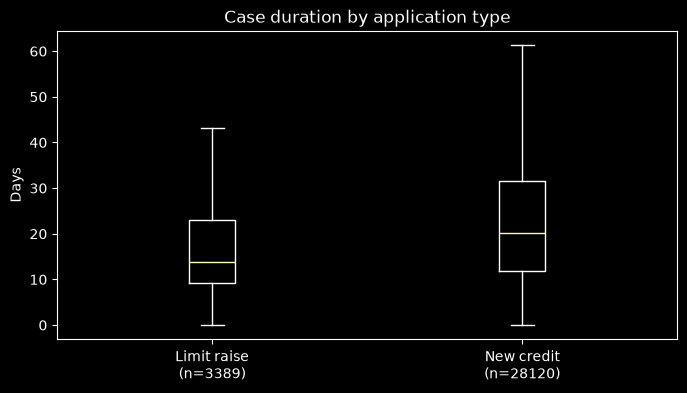

In [ ]:
# Outcome by loan attributes





order = cases.groupby("app_type")["duration_days"].median().sort_values().index
data = [cases.loc[cases["app_type"] == k, "duration_days"] for k in order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(data, showfliers=False)
ax.set_xticklabels([f"{k}\n(n={len(v)})" for k, v in zip(order, data)])
ax.set(title="Case duration by application type", ylabel="Days")
plt.show()

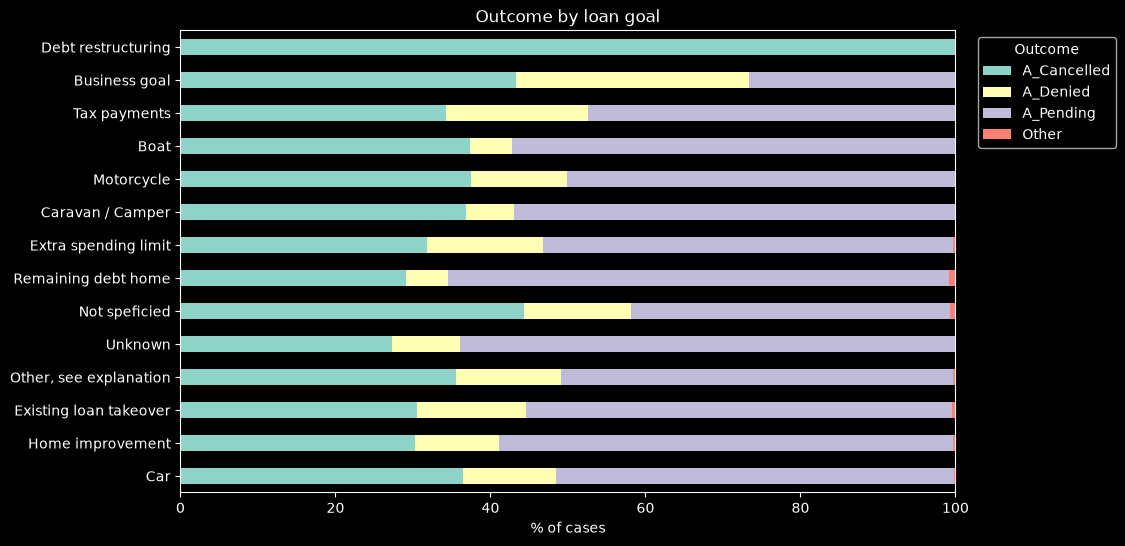

In [ ]:
ct = pd.crosstab(cases["loan_goal"], cases["outcome"], normalize="index") * 100
ct = ct.loc[cases["loan_goal"].value_counts().index]   # biggest groups first

ax = ct.plot(kind="barh", stacked=True, figsize=(10, 6))
ax.set(title="Outcome by loan goal", xlabel="% of cases", ylabel="")
ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### **3.3 Process Model Creation and Validation**

In [ ]:
# The BPIC-17 log has several lifecycle transitions per activity (start, complete, suspend, and so on),
# A common first design decision is to keep only complete events. You can test both and justify your choice in the report.

log = df[df["lifecycle:transition"] == "complete"].copy()
print(len(log), log["case:concept:name"].nunique())

475306 31509


### **3.4 Advanced Analysis**

#### Option 2: Advanced Data Science Analysis

Overall accepted: 54.8 %   |   Limit raise: 73.4 % (n=3,387)   New credit: 52.6 % (n=28,024)


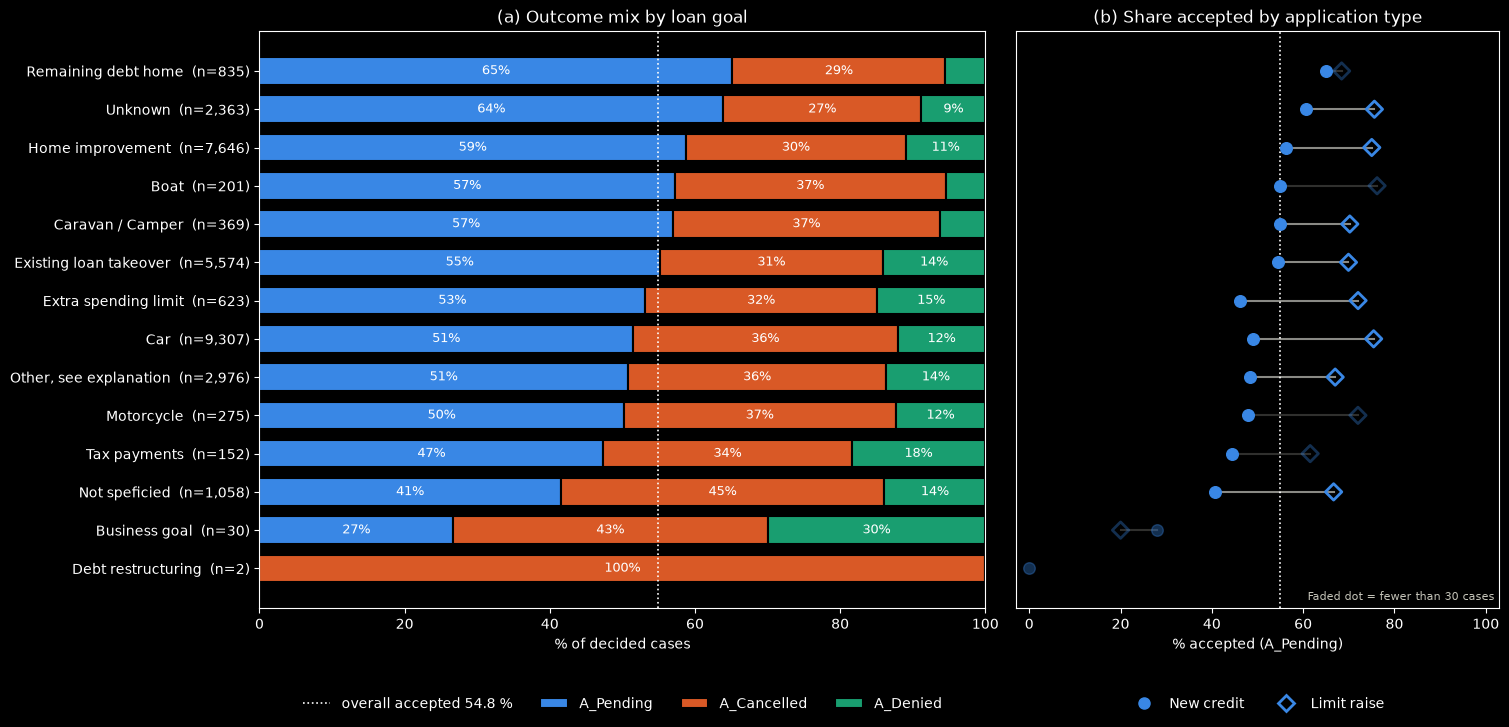

In [37]:
# %% Additional statistic 2: outcome by loan goal, split by application type
OUT = ["A_Pending", "A_Cancelled", "A_Denied"]
COL = {"A_Pending": "#3987e5", "A_Cancelled": "#d95926", "A_Denied": "#199e70"}   # same colours as the duration figure
FADE_BELOW = 30   # dots based on fewer cases than this are drawn faded (small sample)

d = cases[cases["outcome"].isin(OUT)].copy()          # only decided cases
d["accepted"] = d["outcome"].eq("A_Pending")

d["goal"] = d["loan_goal"]                           # every loan goal gets its own row

# table: outcome mix + acceptance rate per application type
mix = pd.crosstab(d["goal"], d["outcome"], normalize="index")[OUT] * 100
by_app = d.groupby(["goal", "app_type"])["accepted"].agg(["mean", "size"]).unstack("app_type")
tab = mix.assign(n=d["goal"].value_counts())
tab["accepted_new_credit"]  = by_app[("mean", "New credit")] * 100
tab["accepted_limit_raise"] = by_app[("mean", "Limit raise")] * 100
tab["share_limit_raise"]    = by_app[("size", "Limit raise")] / tab["n"] * 100
tab = tab.sort_values("A_Pending")                    # lowest acceptance first -> highest ends up on topdisplay(tab.round(1))

overall = d["accepted"].mean() * 100
by_type = d.groupby("app_type")["accepted"].agg(["mean", "size"])
print(f"Overall accepted: {overall:.1f} %   |   " +
      "   ".join(f"{k}: {r['mean']*100:.1f} % (n={int(r['size']):,})" for k, r in by_type.iterrows()))

# figure
plt.style.use("dark_background")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5), sharey=True,
                               gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.05})
y = np.arange(len(tab))
labels = [f"{g}  (n={int(n):,})" for g, n in zip(tab.index, tab["n"])]

# (a) 100 % stacked bars: outcome mix per loan goal
left = np.zeros(len(tab))
for o in OUT:
    ax1.barh(y, tab[o], left=left, color=COL[o], height=0.72, label=o, edgecolor="black", linewidth=1.5)
    for yi, (l, w) in enumerate(zip(left, tab[o])):
        if w >= 8:
            ax1.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += tab[o].values
ax1.axvline(overall, color="white", linestyle=":", linewidth=1.2, label=f"overall accepted {overall:.1f} %")
ax1.set(xlim=(0, 100), xlabel="% of decided cases", title="(a) Outcome mix by loan goal")
ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False)

# (b) share accepted, split by application type (dumbbell)
for yi, g in enumerate(tab.index):
    nc, lr = tab.loc[g, "accepted_new_credit"], tab.loc[g, "accepted_limit_raise"]
    n_lr = by_app.loc[g, ("size", "Limit raise")]
    n_nc = by_app.loc[g, ("size", "New credit")]
    show_lr = pd.notna(lr)                            # no Limit raise cases for a goal -> no diamond
    show_nc = pd.notna(nc)
    a_lr = 1.0 if show_lr and n_lr >= FADE_BELOW else 0.35
    a_nc = 1.0 if show_nc and n_nc >= FADE_BELOW else 0.35
    if show_lr and show_nc:
        ax2.plot([nc, lr], [yi, yi], color="#8a8a85", linewidth=1.5, alpha=min(a_lr, a_nc), zorder=1)
    if show_lr:
        ax2.scatter(lr, yi, marker="D", s=70, facecolors="none", edgecolors=COL["A_Pending"],
                    linewidths=2, alpha=a_lr, zorder=3)
    if show_nc:
        ax2.scatter(nc, yi, marker="o", s=70, color=COL["A_Pending"], alpha=a_nc, zorder=3)
ax2.axvline(overall, color="white", linestyle=":", linewidth=1.2)
ax2.set(xlim=(-3, 103), xlabel="% accepted (A_Pending)", title="(b) Share accepted by application type")
ax2.tick_params(axis="y", left=False)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=COL["A_Pending"], label="New credit"),
           Line2D([], [], marker="D", linestyle="", markersize=8, markerfacecolor="none",
                  markeredgecolor=COL["A_Pending"], markeredgewidth=2, label="Limit raise")]
ax2.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax2.text(0.99, 0.01, f"Faded dot = fewer than {FADE_BELOW} cases", transform=ax2.transAxes,
         ha="right", va="bottom", fontsize=8, color="#c3c2b7")

plt.show()

